Recover convective power and magnetic energy from dynamo simulation 
=====
***

In [2]:
using Plots
using Distributions
using StatsBase
using DelimitedFiles
using Interpolations

Constants

In [4]:
kyr = 1.0e3
mT = 1.0e-3
TW = 1.0e12;
sectoyear = 365.25 * 24 * 60 * 60

# geometry 
b = 3.48e6
c = 1.22e6
L = b - c
Vnd = 4 * pi * ((b/L)^3 - (c/L)^3)/3
V = Vnd * L^3

# physical properties
ρ = 1.1e4
ν = 1.12e-3
σ = 0.97e6;
μ = 4 * π * 1.0e-7
η = 1 /(μ * σ)
Ω_true = 0.7292e-4;

# scales
vscale = ν/L
pscale = ρ * V  * ν^3 / L^4
escale = ρ * ν^2 / L^2
tscale = (L^2 / ν)/sectoyear
escale

2.701542798966246e-15

Read convective power

In [6]:
data = readdlm("power3.dat")
tp = (data[1:end,1].-data[1,1])*tscale;
p = data[1:end,2] * pscale;
vd = data[1:end,3] * pscale;
od = data[1:end,4] * pscale;

ndata = length(tp)

4920

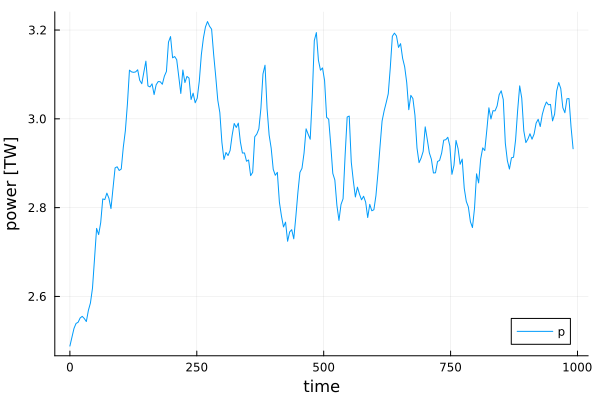

In [7]:
idecimate = 20;
plot(tp[1:idecimate:end],p[1:idecimate:end]/TW,
    xlabel="time",
    ylabel="power [TW]",label="p")

In [8]:
println("mean = ",mean(p)," std= ",std(p))

mean = 2.9517541155284746e12 std= 1.454398512991385e11


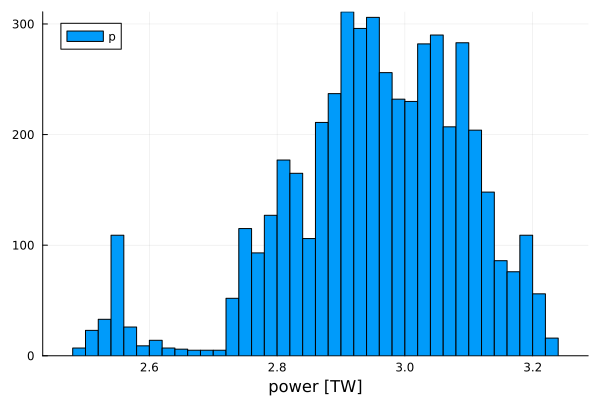

In [9]:
histogram(p/TW,xlabel="power [TW]",label="p")

Compute autcorrelation function (no need to interpolate)

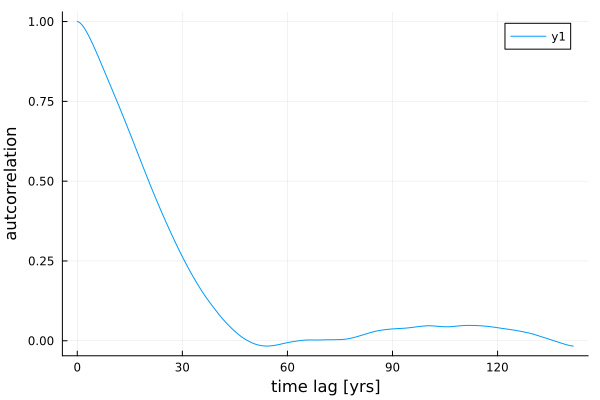

In [11]:
lag = (0 : 700)
dt = tp[2]-tp[1]
c = autocor(p[400:end],lag,demean=true)   # remove first 400 entries
plot(lag * dt, c,
    xlabel="time lag [yrs]",
    ylabel="autcorrelation")

In [12]:
tau = 0.0;

for i = 1 : length(lag)-1
    tau = tau + 0.5*(c[i]+c[i+1])*dt
end
taup = lag[findfirst(y->y < exp(-1.0),c)]

print(" Integrated correlation time = " ,tau," yr")
print("\n Point correlation time = ",taup*dt," yr")

 Integrated correlation time = 23.30115098468683 yr
 Point correlation time = 25.693699774380814 yr

Read magnetic energy

In [14]:
data = readdlm("e_mag3.dat")
tm = (data[1:end,1].-data[1,1])*tscale;
me = data[1:end,2] * escale;
m = 2 * me /ρ

ndata = length(me)
println("mean = ",2*mean(me)/ρ,"  std = ",2*std(me)/ρ)

mean = 0.0012666575900299184  std = 4.613312956120317e-5


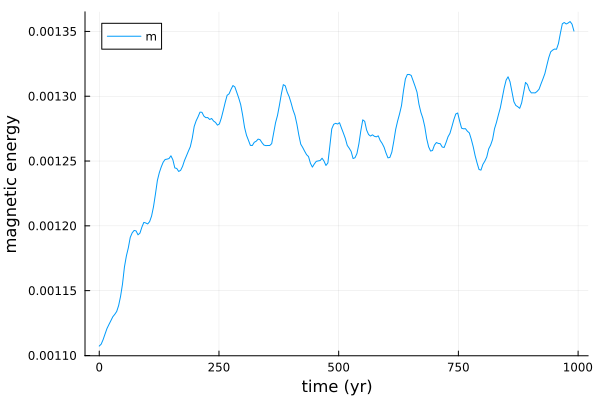

In [15]:
idecimate = 20;
plot(tm[1:idecimate:end],m[1:idecimate:end],
    xlabel="time (yr)",
    ylabel="magnetic energy",label="m")

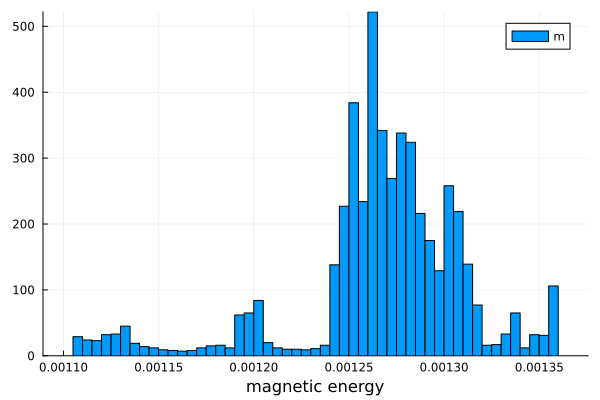

In [16]:
histogram(m,xlabel="magnetic energy",label="m")

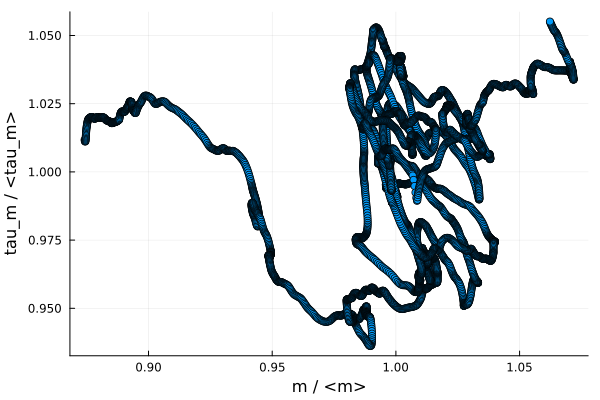

In [17]:
τm = 2*me./od
mvariation = me/mean(me);
plot(me/mean(me),τm/mean(τm),
    st=:scatter,
    xlabel = "m / <m>", 
    ylabel="tau_m / <tau_m>",
    legend=nothing)

In [18]:
ndata = length(τm)
sum1 = 0.0;
sum2 = 0.0;
mtd = mean(τm)
mvariation = me/mean(me)

for i = 1 : ndata
    sum1 = sum1 + (mvariation[i]-1) * (τm[i]/mtd - mtd/mtd)
    sum2 = sum2 + (mvariation[i]-1)^2
end
slope = sum1/sum2

0.050388784817751366

In [19]:
data = readdlm("e_kin.dat")
tv = (data[1:end,1].-data[1,1])*tscale;
ke = data[1:end,2]*escale;

ndata = length(tv)

4920

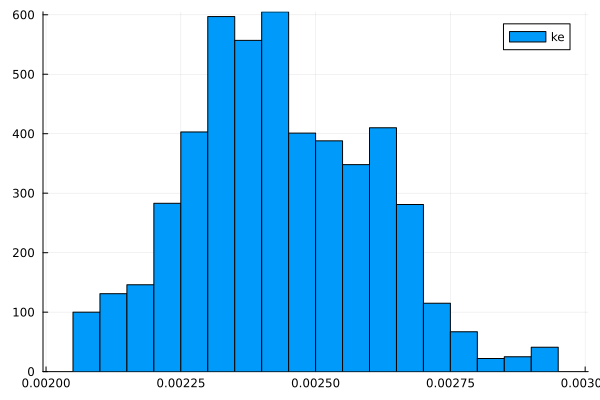

In [20]:
histogram(ke,label="ke")

Overturn time

In [22]:
velocity = sqrt(2 * mean(ke)/ρ)
println(L / (velocity * sectoyear)," yr")

107.66560346842095 yr


Compute time derivative

In [24]:
ndata = length(tv)
dke = zeros(ndata)
dme = zeros(ndata)

for i = 2 : ndata
    dke[i] = (ke[i]-ke[i-1])/(tv[i] - tv[i-1]) 
    dme[i] = (me[i]-me[i-1])/(tm[i]-tm[i-1]) 
end

dke[1] = dke[2]
dme[1] = dme[2]

0.004978113929323617

In [25]:
# ratio of standard deviations
std(dke)/std(dme)

0.0025883184600244222

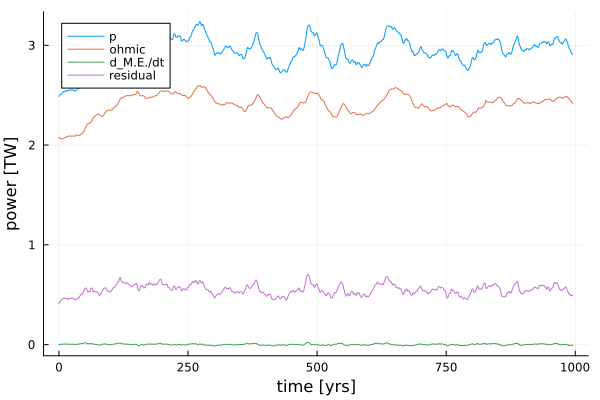

In [26]:
plot(tv,p/TW,xlabel="time [yrs]",ylabel="power [TW]",label="p")
plot!(tv,od/TW,label="ohmic")
plot!(tv,dme,label="d_M.E./dt")
plot!(tv,(p-od-vd-dke-dme)/TW,label="residual")

In [27]:
# save to file ?
save_file = false

pc = (p - vd - dke) / (ρ * V);   # express as density
      
if save_file
    open("power_corrected.txt","w")  do io
        writedlm(io,[tp pc])
    end
end